# Notebook 2: Mechanosensitive Channel Expression by TBI Status and Brain Region

## Aims
1. Visualise expression of each channel gene across TBI vs no-TBI donors
2. Compare expression across the four brain regions
3. Look for genes that show the most striking differences
4. Apply log-transformation to prepare data for statistical modelling

## Data
- `master_analysis_table.csv` — built in Notebook 1

# Notebook 2: Mechanosensitive Channel Expression by TBI Status and Brain Region

## Aims
1. Visualise expression of each channel gene across TBI vs no-TBI donors
2. Compare expression across the four brain regions
3. Look for genes that show the most striking differences
4. Apply log-transformation to prepare data for statistical modelling

## Data
- `master_analysis_table.csv` — built in Notebook 1

# Notebook 2: Mechanosensitive Channel Expression by TBI Status and Brain Region

## Aims
1. Visualise expression of each channel gene across TBI vs no-TBI donors
2. Compare expression across the four brain regions
3. Look for genes that show the most striking differences
4. Apply log-transformation to prepare data for statistical modelling

## Data
- `master_analysis_table.csv` — built in Notebook 1

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# paths
PROJECT_ROOT = Path("..").resolve()
DATA_DIR     = PROJECT_ROOT / "data"
FIGURES_DIR  = PROJECT_ROOT / "figures"

# load master table built in Notebook 1
merged = pd.read_csv(DATA_DIR / "master_analysis_table.csv")

# gene list
target_genes = [
    'PIEZO1', 'PIEZO2', 'TRPV4', 'TRPV1', 'TRPV2',
    'KCNK2', 'KCNK4', 'KCNK10', 'TMEM63A', 'TMEM63B'
]

print(f"Loaded {merged.shape[0]} samples x {merged.shape[1]} columns")
print(f"TBI groups: {merged['ever_tbi_w_loc'].value_counts().to_dict()}")

Loaded 377 samples x 23 columns
TBI groups: {'N': 198, 'Y': 179}


In [3]:
# log-transform expression values
# we use log2(FPKM + 1) — the +1 avoids log(0) errors for zero-expression samples
# this is the standard transformation for FPKM data

for gene in target_genes:
    merged[f'{gene}_log2'] = np.log2(merged[gene] + 1)

log_genes = [f'{gene}_log2' for gene in target_genes]

print("Log-transformation applied.")
print("\nExample — PIEZO1 before and after:")
print(f"  Raw range:   {merged['PIEZO1'].min():.2f} – {merged['PIEZO1'].max():.2f}")
print(f"  Log2 range:  {merged['PIEZO1_log2'].min():.2f} – {merged['PIEZO1_log2'].max():.2f}")

Log-transformation applied.

Example — PIEZO1 before and after:
  Raw range:   0.21 – 6.54
  Log2 range:  0.27 – 2.92


/var/folders/f1/jcfwngdx13v2j40b0dqkyqch0000gp/T/ipykernel_58396/822759302.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/f1/jcfwngdx13v2j40b0dqkyqch0000gp/T/ipykernel_58396/822759302.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/f1/jcfwngdx13v2j40b0dqkyqch0000gp/T/ipykernel_58396/822759302.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/f1/jcfwngdx13v2j40b0dqkyqch0000gp/T/ipykernel_58396/822759302.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and w

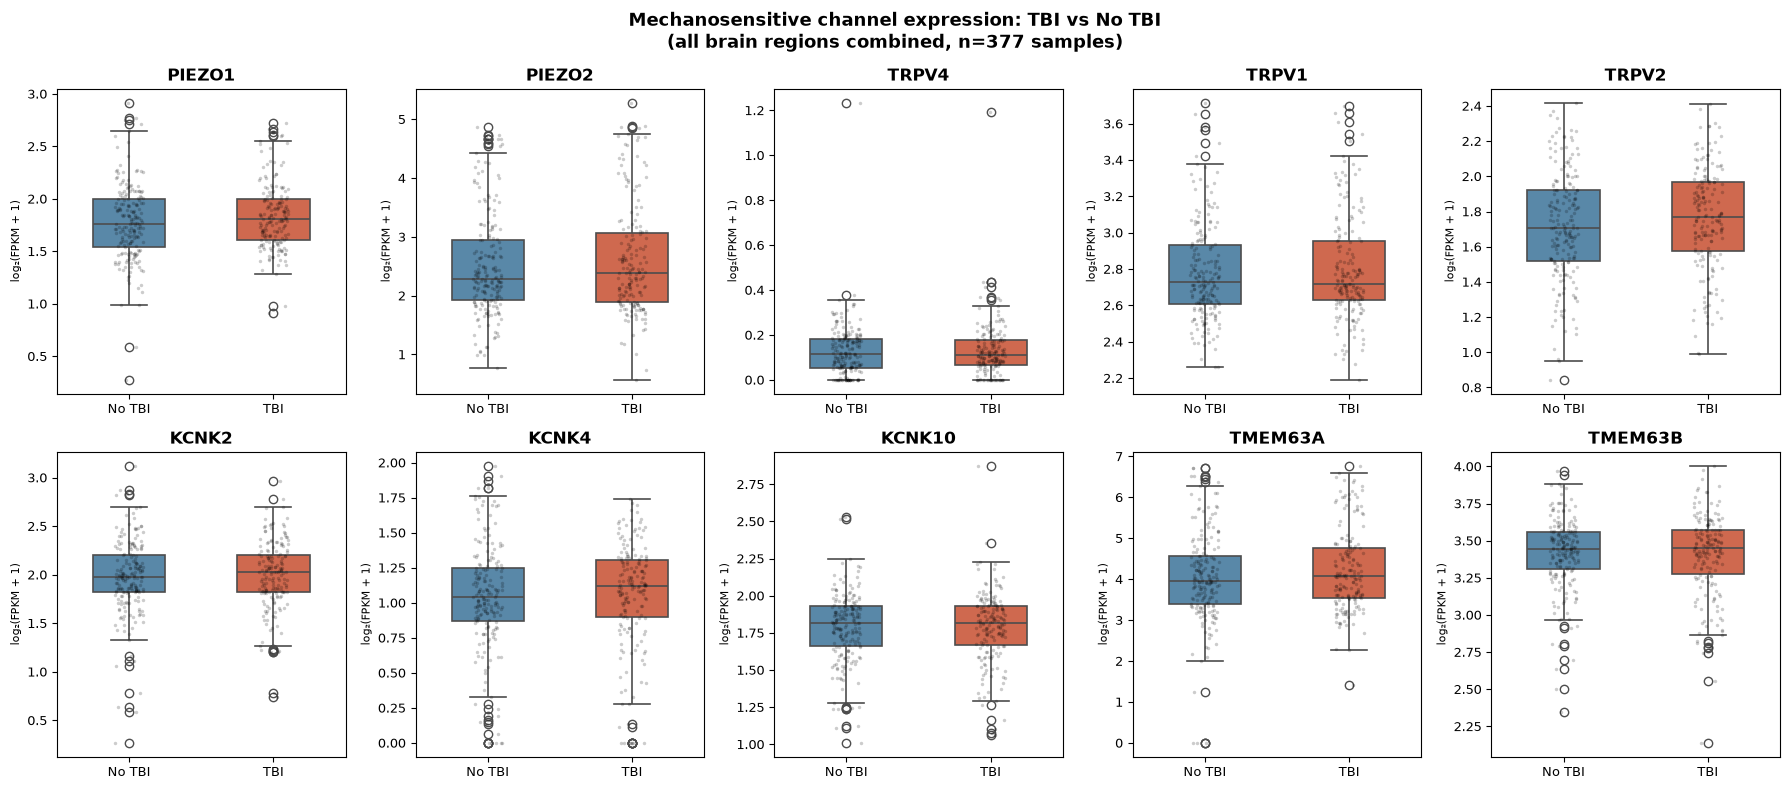

Saved.


In [4]:
# boxplots: expression of each gene in TBI vs no-TBI donors
# this is the main visual answer to question 1 of your project

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

# nicer labels for the plot
tbi_labels = {'Y': 'TBI', 'N': 'No TBI'}
merged['TBI_label'] = merged['ever_tbi_w_loc'].map(tbi_labels)
palette = {'TBI': '#E45C3A', 'No TBI': '#4C8BB5'}

for i, gene in enumerate(target_genes):
    sns.boxplot(
        data=merged,
        x='TBI_label', y=f'{gene}_log2',
        palette=palette,
        order=['No TBI', 'TBI'],
        ax=axes[i],
        width=0.5,
        linewidth=1.2
    )
    # overlay individual data points
    sns.stripplot(
        data=merged,
        x='TBI_label', y=f'{gene}_log2',
        order=['No TBI', 'TBI'],
        ax=axes[i],
        color='black', alpha=0.2, size=2.5
    )
    axes[i].set_title(gene, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('log₂(FPKM + 1)', fontsize=8)
    axes[i].tick_params(labelsize=9)

plt.suptitle('Mechanosensitive channel expression: TBI vs No TBI\n(all brain regions combined, n=377 samples)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_expression_by_TBI.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved.")

/var/folders/f1/jcfwngdx13v2j40b0dqkyqch0000gp/T/ipykernel_58396/202761306.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/f1/jcfwngdx13v2j40b0dqkyqch0000gp/T/ipykernel_58396/202761306.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/f1/jcfwngdx13v2j40b0dqkyqch0000gp/T/ipykernel_58396/202761306.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/f1/jcfwngdx13v2j40b0dqkyqch0000gp/T/ipykernel_58396/202761306.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is depreca

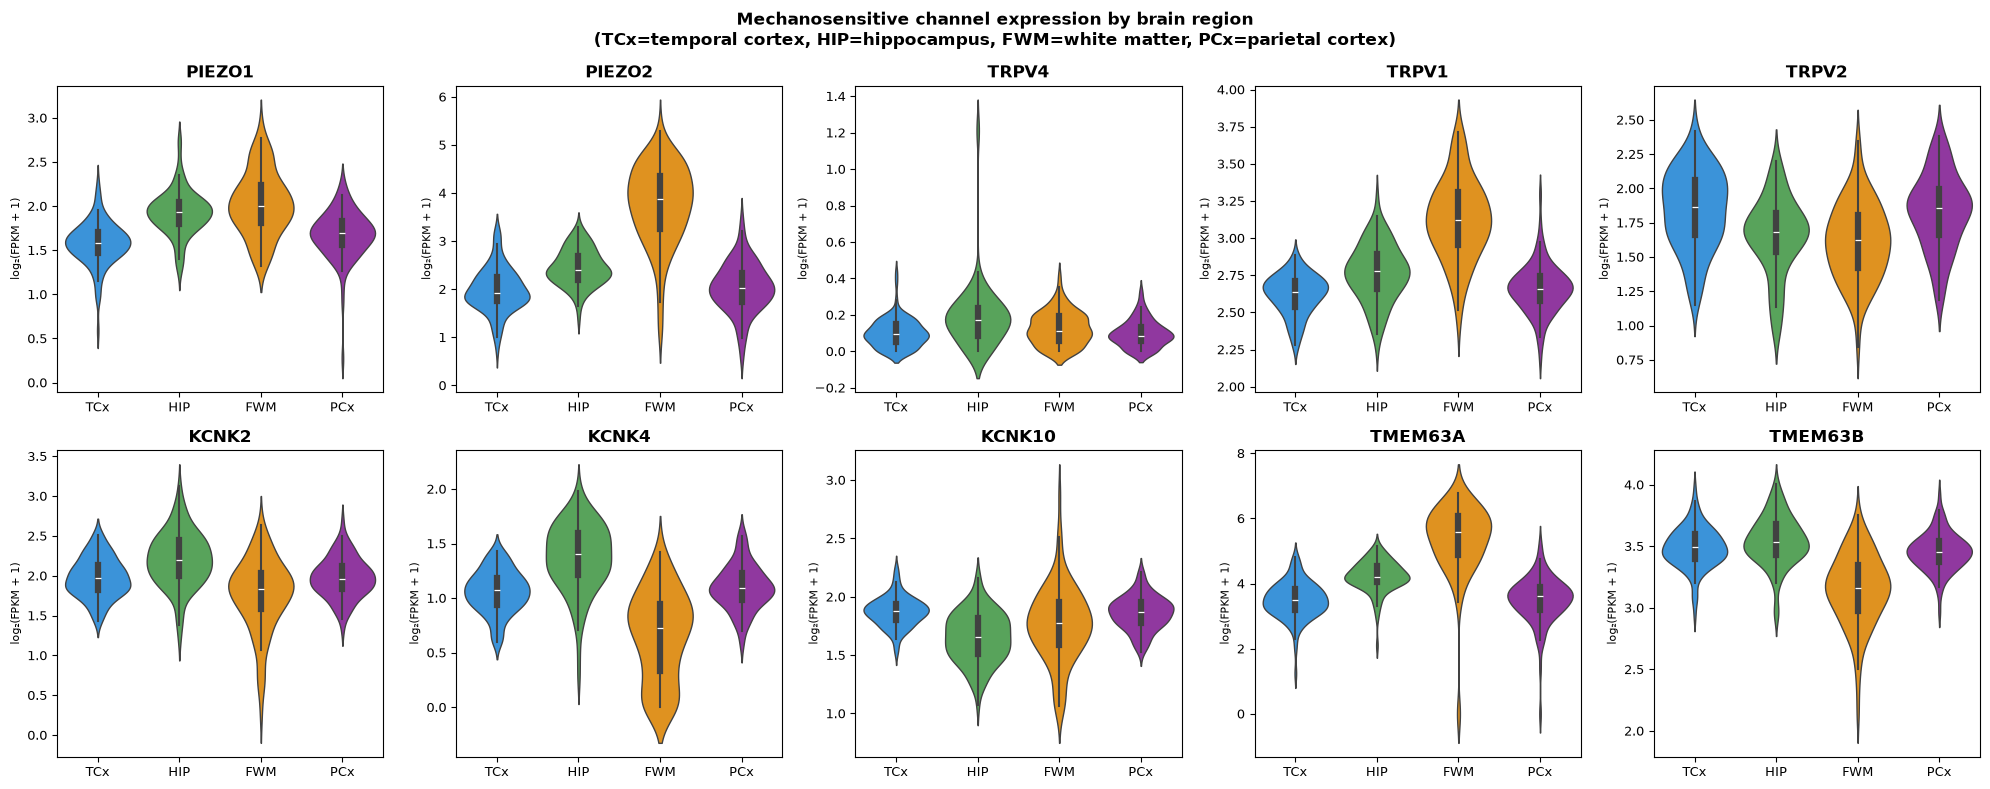

Saved.


In [5]:
# create a short region label for cleaner plots
region_map = {
    'temporal neocortex': 'TCx',
    'hippocampus (hippocampal formation)': 'HIP',
    'white matter of forebrain': 'FWM',
    'parietal neocortex': 'PCx'
}
merged['region'] = merged['structure_name'].map(region_map)

# plot expression by brain region for each gene
# using violin plots which show the full distribution shape
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

region_palette = {
    'TCx': '#2196F3',
    'HIP': '#4CAF50', 
    'FWM': '#FF9800',
    'PCx': '#9C27B0'
}

for i, gene in enumerate(target_genes):
    sns.violinplot(
        data=merged,
        x='region', y=f'{gene}_log2',
        palette=region_palette,
        order=['TCx', 'HIP', 'FWM', 'PCx'],
        ax=axes[i],
        inner='box',
        linewidth=1.0
    )
    axes[i].set_title(gene, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('log₂(FPKM + 1)', fontsize=8)
    axes[i].tick_params(labelsize=9)

plt.suptitle('Mechanosensitive channel expression by brain region\n(TCx=temporal cortex, HIP=hippocampus, FWM=white matter, PCx=parietal cortex)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_expression_by_region.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved.")

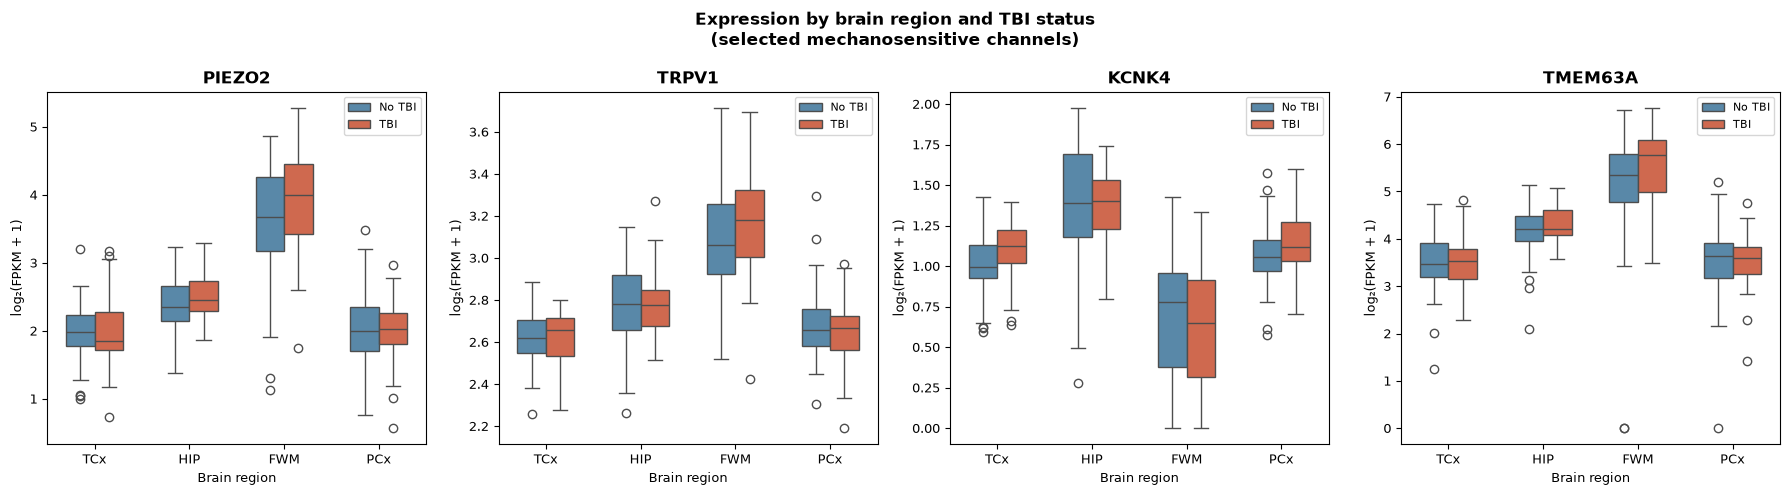

Saved.


In [6]:
# split by both region AND TBI status
# using just the three most interesting genes to keep it readable
key_genes = ['PIEZO2', 'TRPV1', 'KCNK4', 'TMEM63A']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

tbi_palette = {'TBI': '#E45C3A', 'No TBI': '#4C8BB5'}
region_order = ['TCx', 'HIP', 'FWM', 'PCx']

for i, gene in enumerate(key_genes):
    sns.boxplot(
        data=merged,
        x='region', y=f'{gene}_log2',
        hue='TBI_label',
        palette=tbi_palette,
        order=region_order,
        hue_order=['No TBI', 'TBI'],
        ax=axes[i],
        width=0.6,
        linewidth=1.0
    )
    axes[i].set_title(gene, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Brain region', fontsize=9)
    axes[i].set_ylabel('log₂(FPKM + 1)', fontsize=9)
    axes[i].tick_params(labelsize=9)
    axes[i].legend(title='', fontsize=8)

plt.suptitle('Expression by brain region and TBI status\n(selected mechanosensitive channels)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_expression_region_by_TBI.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved.")